## Mira primero: una plantilla, tres planos

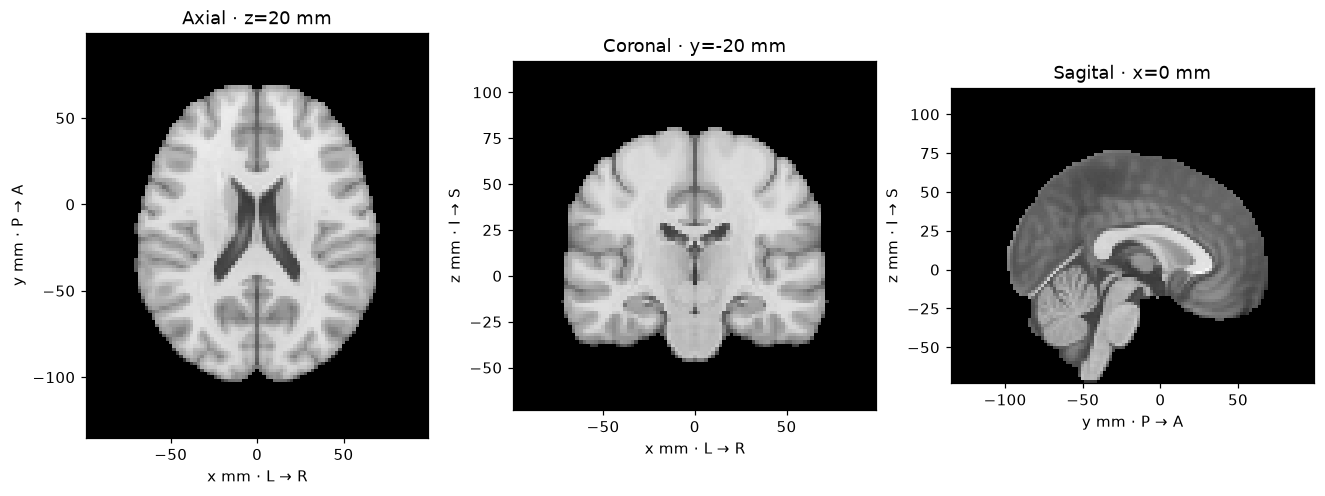

**Estas imágenes ya están aquí:** puedes observarlas sin ejecutar ni instalar nada. Son tres cortes de la misma plantilla de referencia, no tres pacientes. Después sigue la ruta y ejecuta el código para reproducirlas.


# Análisis de datos médicos
## Taller en vivo: imágenes médicas con Python · 60 minutos

**Juan Calderón · Escuela de Machine Learning y Data Science en Honduras**  
**Viernes 27 de noviembre de 2026 · 13:30–14:30, hora de Honduras (UTC−6).**  
Horario del [programa público de la escuela](https://machine-learning-honduras.org/programa/), consultado el 23 de noviembre de 2026.

La primera salida muestra imágenes. Trabajaremos con una **plantilla cerebral pública**, no con un estudio privado ni con un diagnóstico. En ocho celdas aprenderemos a explorar cortes, contar intensidades, seleccionar píxeles y comparar operaciones. No entrenaremos un modelo ni analizaremos EEG.

**Para participar:** computadora, navegador y conexión. En Google Colab usa el entorno normal de **CPU**; no necesitas GPU ni montar Drive. Ejecuta cada celda con el triángulo o **Mayús + Enter** y espera a que termine. Las figuras ya están guardadas: puedes mirar antes de ejecutar.

La primera celda usa la copia pública local si está disponible; de lo contrario obtiene la plantilla distribuida por Nilearn. Solo instala bibliotecas que faltan y registra las versiones utilizadas. La instalación inicial puede tardar: conviene ejecutar esa celda **antes de comenzar la hora de clase**. Si falta una dependencia local, necesitas internet para prepararla. No cambies versiones durante la sesión; si aparece un error de importación, consulta al facilitador antes de continuar.

| Minutos | Celdas | Qué haremos |
|---|---|---|
| 0–10 | 1 | Mirar la plantilla y reconocer tres planos |
| 10–20 | 2 | Mover un corte y cambiar su contraste |
| 20–35 | 3–4 | Leer un histograma y modificar un percentil |
| 35–43 | 5 | Distinguir una curva de una región seleccionada |
| 43–55 | 6–7 | Comparar filtros y respuestas de borde |
| 55–60 | 8 | Explicar lo aprendido con tres preguntas |

Las explicaciones de cada línea son **consulta posterior**. En clase observa, predice un cambio y prueba solo el parámetro indicado. Las soluciones aparecen en apartados separados para revisarlas después de tu intento. Si cambias un corte o reinicias el entorno, vuelve a ejecutar las celdas siguientes en orden.

[Página del taller](https://fisikmedik.github.io/taller-imagenes-medicas-python/) · [Repositorio y descargas](https://github.com/FisikMedik/taller-imagenes-medicas-python) · [Manual ilustrado](https://github.com/FisikMedik/taller-imagenes-medicas-python/blob/main/Guia_visual_imagenes_medicas.pdf) · [Cuaderno completo de 24 lecciones](https://github.com/FisikMedik/taller-imagenes-medicas-python/blob/main/Taller_imagenes_medicas.ipynb)

## Celda 1 · Primero miremos: una plantilla, tres planos

**0–10 minutos · Demostración guiada.** No requiere ninguna otra celda. Ejecuta y mira primero las tres imágenes. Son distintas secciones del mismo volumen de referencia.

Una imagen 2D es una tabla de valores; un volumen añade una tercera dirección. Su elemento se llama **vóxel**. Los índices indican posiciones en la tabla; la información geométrica permite expresarlas en milímetros. Aquí los centros vecinos están separados por **2 mm**. La orientación y el espaciado se comprueban antes de dibujar: estas simplificaciones pertenecen a la plantilla de esta práctica.

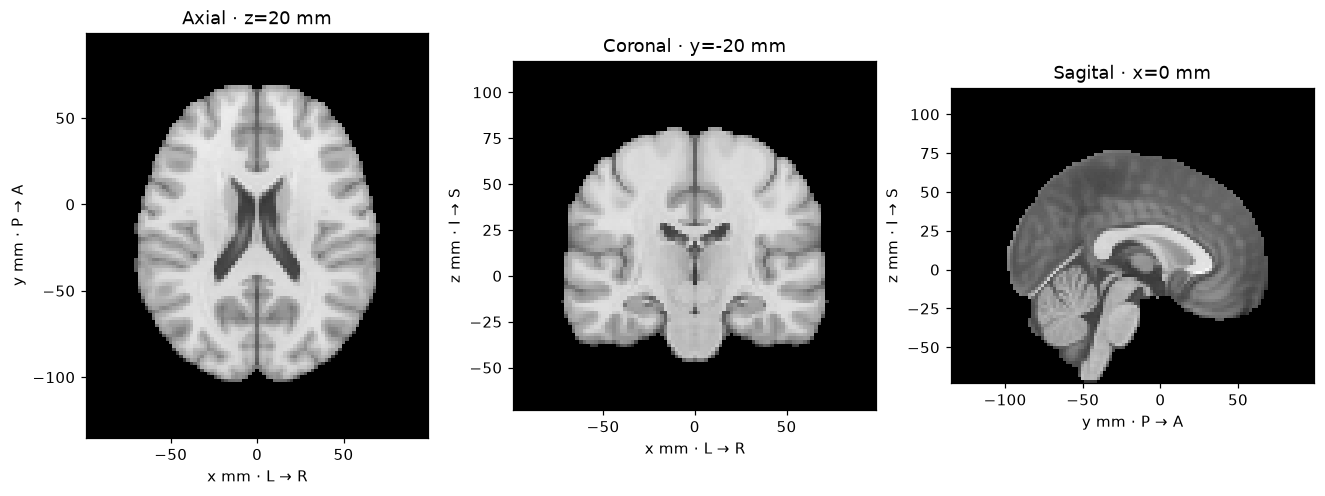

Copia pública local: datos/mni152_2mm.nii.gz
Volumen: (99, 117, 95) · espaciado: [2. 2. 2.] mm · Python 3.12.14
Versiones: numpy 2.5.4, matplotlib 3.11.2, nibabel 5.4.2, scipy 1.18.1


In [1]:
import sys, subprocess, importlib.util
from pathlib import Path
from importlib.metadata import version
ruta = Path("datos/mni152_2mm.nii.gz")
requisitos = {"numpy": "numpy>=1.22.4,<3", "matplotlib": "matplotlib>=3.8,<4", "nibabel": "nibabel>=5.2,<6", "scipy": "scipy>=1.8,<2"}
if not ruta.exists():
    requisitos["nilearn"] = "nilearn==0.12.1"
faltantes = [paquete for modulo, paquete in requisitos.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    instalacion = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltantes], capture_output=True, text=True)
    if instalacion.returncode != 0:
        raise RuntimeError("No terminó la preparación. Revisa la conexión y consulta al facilitador. " + instalacion.stderr[-1200:])
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from scipy import ndimage
if ruta.exists():
    imagen = nib.load(ruta)
    fuente = "Copia pública local: datos/mni152_2mm.nii.gz"
else:
    from nilearn.datasets import load_mni152_template
    imagen = load_mni152_template(resolution=2)
    fuente = "Plantilla distribuida por Nilearn " + version("nilearn")
imagen = nib.as_closest_canonical(imagen)
datos = imagen.get_fdata(dtype=np.float32)
pasos = np.array(imagen.header.get_zooms()[:3])
afin = imagen.affine
assert datos.shape == (99, 117, 95) and np.allclose(pasos, [2, 2, 2]), "La entrada no coincide con la plantilla docente de 2 mm."
assert nib.aff2axcodes(afin) == ("R", "A", "S") and np.allclose(afin[:3, :3], np.diag(pasos)), "Revisa la orientación de la entrada."
assert np.isfinite(datos).all() and datos.min() >= 0 and datos.max() <= 1, "Revisa el rango de la plantilla."
x, y, z = [afin[eje, 3] + pasos[eje] * np.arange(datos.shape[eje]) for eje in range(3)]
extension = [x[0]-1, x[-1]+1, y[0]-1, y[-1]+1]
cortes = [datos[:, :, 46].T, datos[:, 57, :].T, datos[49, :, :].T]
extensiones = [extension, [x[0]-1, x[-1]+1, z[0]-1, z[-1]+1], [y[0]-1, y[-1]+1, z[0]-1, z[-1]+1]]
titulos = [f"Axial · z={z[46]:.0f} mm", f"Coronal · y={y[57]:.0f} mm", f"Sagital · x={x[49]:.0f} mm"]
ejes = [("x mm · L → R", "y mm · P → A"), ("x mm · L → R", "z mm · I → S"), ("y mm · P → A", "z mm · I → S")]
fig, ax = plt.subplots(1, 3, figsize=(12, 4.4), layout="constrained")
for panel, matriz, limites, titulo, etiquetas in zip(ax, cortes, extensiones, titulos, ejes):
    panel.imshow(matriz, cmap="gray", origin="lower", extent=limites, vmin=0, vmax=1)
    panel.set(title=titulo, xlabel=etiquetas[0], ylabel=etiquetas[1])
plt.show()
print(f"{fuente}\nVolumen: {datos.shape} · espaciado: {pasos} mm · Python {sys.version.split()[0]}")
print("Versiones: " + ", ".join(f"{nombre} {version(nombre)}" for nombre in requisitos))

### Observa y responde

¿Son tres pacientes?

<details>
<summary>Ver la respuesta después de intentarlo</summary>

**No.** Son tres planos de una misma plantilla poblacional.

</details>

 Una plantilla facilita aprender y situar resultados; no es un caso individual ni una cohorte para evaluar un diagnóstico. RAS+ describe direcciones, no garantiza alineación anatómica entre dos archivos.

**Preparación alternativa, solo si hace falta:** para trabajar localmente, descarga el repositorio completo y prepara sus bibliotecas con `requirements.txt` antes del taller. En Colab, las dependencias ausentes se preparan automáticamente. El material se comprobó con Nilearn 0.12.1; si ya había otra versión, se conserva y se muestra la versión real, y las comprobaciones de geometría/rango deben seguir pasando. No hay que ejecutar comandos de instalación adicionales cuando la celda ya termina correctamente.

### Cada línea, para consultar después

1. Importa herramientas para comprobar qué bibliotecas existen y preparar las que falten en este mismo Python.
2. Path representa la ubicación de un archivo sin depender de cómo se escriben las rutas en cada sistema.
3. version permite informar qué versiones de las bibliotecas se están utilizando.
4. Busca la copia pública de la plantilla junto al cuaderno, dentro de datos.
5. Declara bibliotecas compatibles; los límites coinciden con los del material completo y no obligan a reinstalarlas.
6. Si no existe la copia local, prepara también el cargador de la plantilla.
7. La versión docente de Nilearn se solicita únicamente si falta esta biblioteca en la ruta alternativa.
8. Identifica paquetes ausentes; conserva las bibliotecas que ya están instaladas.
9. Solo ejecuta la instalación si hace falta alguna dependencia.
10. Instala lo necesario y guarda los mensajes técnicos para que la primera salida normal sea la imagen.
11. Comprueba que la preparación terminó correctamente.
12. Detiene el proceso con información útil si una instalación falla; no continúa con un entorno incompleto.
13. NumPy guarda y calcula con matrices; usaremos el nombre breve np.
14. Matplotlib dibuja las imágenes y sus ejes.
15. NiBabel abre el archivo NIfTI y lee su información espacial.
16. SciPy ofrece los filtros y el operador Sobel que utilizaremos más adelante.
17. Elige primero la copia pública incluida en el repositorio.
18. Abre el archivo local; no necesita descargar la plantilla.
19. Registra la ruta de procedencia utilizada en esta ejecución.
20. Si Colab abrió solo el cuaderno, utiliza la alternativa incluida en Nilearn.
21. Importa la función que proporciona la plantilla de referencia.
22. Obtiene la plantilla remuestreada a una rejilla de 2 mm.
23. Registra la versión real del proveedor, sin inventar qué versión está instalada.
24. Reordena los ejes hacia RAS+ conservando la geometría; no registra dos cerebros entre sí.
25. Obtiene la matriz del volumen con números decimales de 32 bits.
26. Lee las distancias entre centros de vóxeles en las tres direcciones de esta plantilla.
27. La afín relaciona los índices de la matriz con las coordenadas físicas.
28. Comprueba las dimensiones y el espaciado esperados antes de usar cortes y fórmulas simplificadas.
29. Verifica que los índices aumentan hacia derecha, anterior y superior y que esta afín no tiene términos oblicuos.
30. Comprueba que los números son finitos y pertenecen al intervalo documentado para esta referencia reescalada.
31. Construye las coordenadas de los centros; la fórmula es válida por la comprobación anterior de la afín.
32. Sitúa los límites del plano axial medio píxel fuera de sus centros; un medio píxel equivale aquí a 1 mm.
33. Extrae un corte axial, uno coronal y uno sagital; T adapta filas y columnas a los ejes del dibujo.
34. Prepara límites físicos coherentes para cada uno de los tres planos.
35. Identifica el plano y deriva su posición de las coordenadas realmente cargadas, sin fijarla a mano.
36. Explica el sentido creciente de cada eje: izquierda/derecha, posterior/anterior e inferior/superior.
37. Reserva tres paneles con espacio para títulos y coordenadas.
38. Recorre las tres vistas emparejando cada una con su geometría y sus etiquetas.
39. Muestra los tres planos con la misma escala de gris de cero a uno.
40. Escribe orientación y unidades junto a cada vista.
41. Presenta las imágenes antes de los mensajes de versiones.
42. Documenta la entrada y el entorno de cálculo después de mirar las imágenes.
43. Informa las versiones instaladas, útiles para reproducir o investigar diferencias.

## Celda 2 · Mover un corte y cambiar su contraste

**10–20 minutos · Primera práctica.** Requiere la celda 1. Elige un plano axial mediante `k` y una ventana de visualización con dos extremos. Cambiar `k` elige otra sección; cambiar la ventana modifica cómo vemos los números del corte.

Un valor bajo se ve oscuro y uno alto, claro. En esta RM los números son intensidades relativas de una plantilla procesada, no probabilidades de enfermedad. Los extremos de la ventana no son instrucciones para borrar o modificar datos.

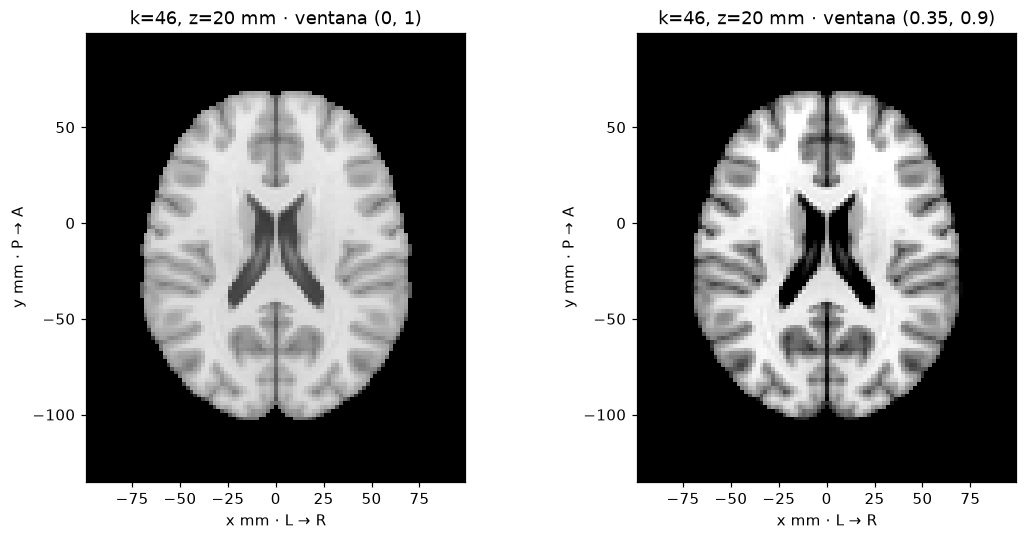

¿La matriz conserva sus valores? True


In [2]:
k = 46
ventana = (0.35, 0.90)
assert 0 <= k < datos.shape[2] and ventana[0] < ventana[1]
corte = datos[:, :, k].T.copy()
fig, ax = plt.subplots(1, 2, figsize=(10, 4.8), layout="constrained")
for panel, limites in zip(ax, [(0, 1), ventana]):
    panel.imshow(corte, cmap="gray", origin="lower", extent=extension, vmin=limites[0], vmax=limites[1])
    panel.set(title=f"k={k}, z={z[k]:.0f} mm · ventana {limites}", xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()
print("¿La matriz conserva sus valores?", np.array_equal(corte, datos[:, :, k].T))

### Prueba antes de consultar la solución

1. Cambia `k` de 46 a 56. ¿Cuántos milímetros se desplazará el plano?
2. Vuelve a `k = 46` y cambia solo `ventana` a `(0.60, 0.80)`. Predice qué ocurrirá con un valor 0.5.

**Pista:** cada salto de índice equivale a 2 mm; un valor menor que el extremo inferior aparece negro.



<details>
<summary>Ver la solución explicada</summary>

Diez índices equivalen a **20 mm**: el plano pasa de z=20 a z=40 mm. Con ventana 0.60–0.80, un valor 0.5 se muestra negro aunque siga valiendo 0.5. La comprobación devuelve `True` porque no hemos modificado la matriz mediante la ventana.

</details>

**Antes de continuar:** restaura `k = 46` y `ventana = (0.35, 0.90)` y ejecuta esta celda. Si mantienes otro corte, las figuras y conteos posteriores cambiarán; no serán los valores de referencia impresos en el manual.

### Cada línea, para consultar después

1. Elige el índice del corte axial; en esta plantilla 46 corresponde a z=20 mm.
2. Define qué intensidades se mostrarán como negro y blanco en el segundo panel.
3. Impide un índice fuera del volumen o una ventana con extremos invertidos.
4. Extrae una copia del plano elegido, organizada con y en filas y x en columnas.
5. Crea dos paneles para comparar el mismo corte.
6. Utiliza una ventana amplia de referencia y otra elegida por el participante.
7. Traduce los mismos valores a grises según cada ventana.
8. Muestra qué plano y qué límites se están comparando.
9. Presenta la comparación.
10. Comprueba que la visualización no modificó el corte extraído.

## Celda 3 · Contar intensidades: el histograma y el fondo

**20–27 minutos · Demostración con predicción.** Requiere las celdas 1–2. El eje horizontal del histograma muestra intensidades; el vertical, cuántos píxeles caen en cada intervalo. El histograma pierde información de ubicación: imágenes con los mismos valores en distinto orden pueden compartirlo.

Comparamos el corte completo con un **soporte** definido por valores mayores que una millonésima. Es una regla práctica para excluir el fondo casi nulo de esta plantilla; no una segmentación cerebral validada.

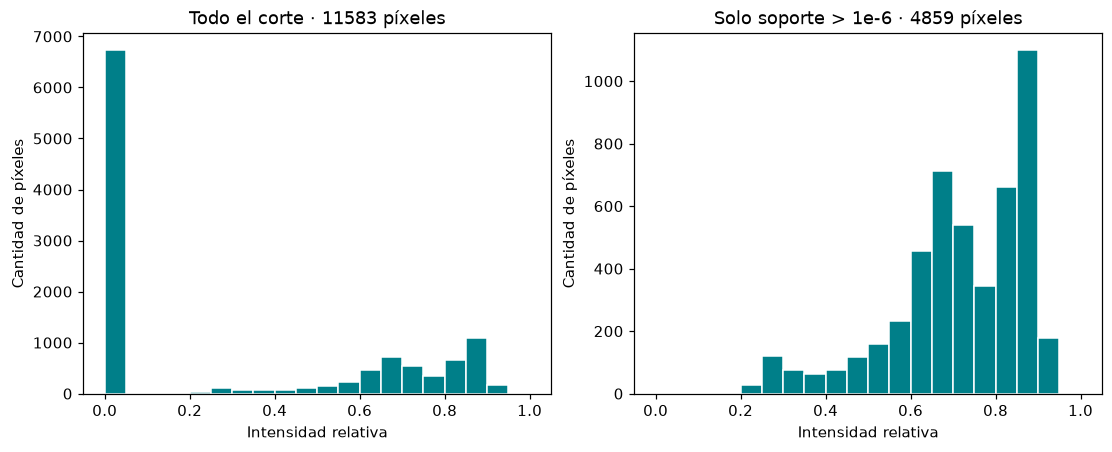

Total: 11583 · soporte: 4859 · excluidos: 6724


In [3]:
bins = 20
soporte = corte > 1e-6
valores = corte[soporte]
fig, ax = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for panel, muestra, nombre in zip(ax, [corte.ravel(), valores], ["Todo el corte", "Solo soporte > 1e-6"]):
    panel.hist(muestra, bins=bins, range=(0, 1), color="#007f89", edgecolor="white")
    panel.set(title=f"{nombre} · {muestra.size} píxeles", xlabel="Intensidad relativa", ylabel="Cantidad de píxeles")
plt.show()
print(f"Total: {corte.size} · soporte: {valores.size} · excluidos: {corte.size-valores.size}")

### Predice

¿Al aumentar `bins` de 20 a 80 aparecerán píxeles nuevos? ¿Cambiará la suma de los conteos? Puedes probarlo si queda tiempo y luego volver a 20.

**Pista:** repartes las mismas fichas entre más cajas. Los intervalos se hacen más estrechos.



<details>
<summary>Ver la solución explicada</summary>

No aparecen píxeles nuevos: cambia la agrupación. Con el corte 46 hay **11 583** posiciones; el soporte tiene **4 859** y se excluyen **6 724**. El histograma con fondo contiene muchos ceros. Las escalas verticales de estos dos paneles son diferentes para hacer visible cada distribución: compara sus números, no solo la altura dibujada. Los picos no identifican tejidos por sí mismos.

</details>

### Cada línea, para consultar después

1. Elige cuántos intervalos de intensidad usaremos entre cero y uno.
2. Selecciona posiciones con intensidad superior a una millonésima y excluye el fondo casi nulo.
3. Reúne las intensidades seleccionadas en una lista de números para analizarlas.
4. Crea un panel para todos los píxeles y otro para el soporte.
5. ravel reúne todos los píxeles; la otra muestra contiene únicamente los seleccionados.
6. Cuenta cuántos valores caen en cada intervalo del rango fijado.
7. Identifica la población contada y los dos ejes del histograma.
8. Presenta los histogramas; sus escalas verticales se ajustan por separado y deben leerse antes de comparar alturas.
9. Documenta el denominador del análisis para que ningún porcentaje quede ambiguo.

## Celda 4 · Elegir un percentil y ver su máscara

**27–35 minutos · Segunda práctica.** Requiere las celdas 1–3. Un percentil es una posición en la lista ordenada de intensidades. El percentil 90 calcula un valor de corte; no significa automáticamente intensidad 0.90.

Una **máscara** guarda verdadero o falso en cada posición. Aquí selecciona píxeles del soporte cuya intensidad alcanza o supera el umbral. Es una regla numérica, sin etiqueta clínica.

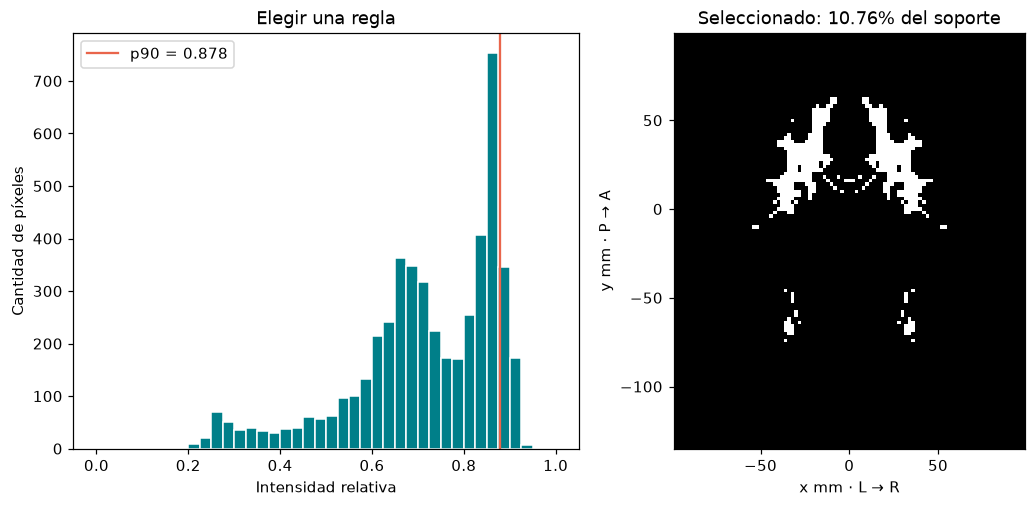

Umbral: 0.878431 · seleccionados: 523 / 4859


In [4]:
percentil = 90
assert 0 <= percentil <= 100
umbral = np.percentile(valores, percentil)
mascara = soporte & (corte >= umbral)
porcentaje = 100 * mascara.sum() / valores.size
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
ax[0].hist(valores, bins=40, range=(0, 1), color="#007f89", edgecolor="white")
ax[0].axvline(umbral, color="#e9654b", label=f"p{percentil} = {umbral:.3f}")
ax[0].legend()
ax[0].set(xlabel="Intensidad relativa", ylabel="Cantidad de píxeles", title="Elegir una regla")
ax[1].imshow(mascara, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1, interpolation="nearest")
ax[1].set(title=f"Seleccionado: {porcentaje:.2f}% del soporte", xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()
print(f"Umbral: {umbral:.6f} · seleccionados: {mascara.sum()} / {valores.size}")

### Prueba antes de consultar la solución

Cambia `percentil` de 90 a 75. Antes de ejecutar, predice si se seleccionarán más o menos posiciones. Conserva el mismo corte y soporte.

**Pista:** bajar el percentil baja o mantiene el umbral. La condición sigue siendo `>=`.



<details>
<summary>Ver la solución explicada</summary>

La selección crece o conserva su tamaño. Con los parámetros originales, p90 da un umbral aproximado de **0.878431** y selecciona **523 de 4 859 píxeles: 10.76 %**. No es exactamente 10 % porque varias posiciones empatan en el valor del umbral. El resultado no mide enfermedad ni volumen de un tejido identificado.

</details>

**Restaura p90** para reproducir las salidas guardadas.

### Cada línea, para consultar después

1. Elige qué posición porcentual de la distribución utilizarás como umbral.
2. Comprueba que el percentil pertenezca al intervalo válido.
3. Calcula el valor de intensidad correspondiente al percentil del soporte.
4. Selecciona únicamente posiciones del soporte que alcanzan o superan ese valor.
5. Divide los seleccionados entre el soporte; no incluye el fondo en el denominador.
6. Reserva un panel para la regla sobre intensidades y otro para su localización.
7. Muestra la distribución de las intensidades que usamos para elegir el umbral.
8. Marca el valor calculado sobre el eje horizontal.
9. Añade la etiqueta que identifica la línea vertical.
10. Mantiene separados intensidad y conteo.
11. Muestra verdadero en blanco y falso en negro sin suavizar los cuadrados.
12. Informa el denominador y mantiene las coordenadas físicas.
13. Presenta criterio y máscara juntos.
14. Conserva el valor y el conteo preciso para comparar ejecuciones.

## Celda 5 · Curvas sobre la plantilla: una línea no es una región

**35–43 minutos · Observación guiada y variación breve.** Requiere las celdas 1–3. La curva sigue posiciones de **igual intensidad**; la máscara selecciona posiciones con intensidad **mayor o igual**. Ambas usan aquí un nivel absoluto de 0.7, que no equivale al percentil 70.

`contour` estima el cruce del nivel entre centros vecinos; no necesita pasar por el centro de un píxel. Usamos x/y en milímetros para alinear las curvas con la imagen. Una misma intensidad puede aparecer en varias regiones separadas y no constituye una frontera anatómica validada.

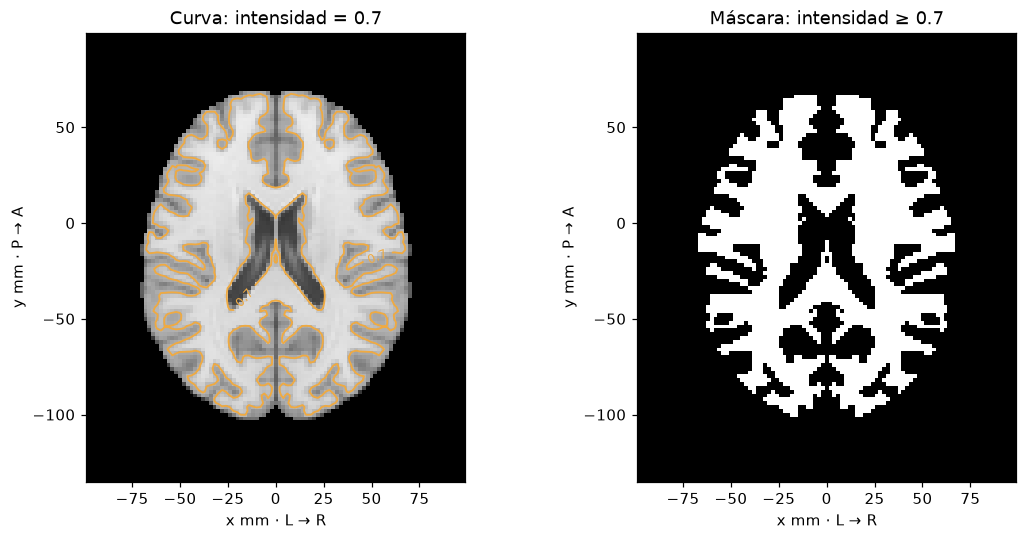

In [5]:
nivel = 0.7
region = soporte & (corte >= nivel)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.8), layout="constrained")
ax[0].imshow(corte, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
lineas = ax[0].contour(x, y, corte, levels=[nivel], colors=["#efaa42"], linewidths=1.2)
ax[0].clabel(lineas, fmt="%.1f", fontsize=8)
ax[1].imshow(region, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1, interpolation="nearest")
for panel, titulo in zip(ax, [f"Curva: intensidad = {nivel}", f"Máscara: intensidad ≥ {nivel}"]):
    panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()

### Prueba y pista

Cambia `nivel` a 0.6 y predice qué ocurrirá con el área blanca. No cambies al mismo tiempo el corte. Una condición menos exigente acepta más posiciones.



<details>
<summary>Ver la solución explicada</summary>

La máscara se amplía o conserva su tamaño. La curva puede cambiar de forma y número de lazos: no es una línea simplemente engrosada. Una curva 0.7 sigue intensidad 0.7; un borde fuerte indica un cambio local grande. **No son sinónimos.**

</details>

Restaura `nivel = 0.7` si deseas reproducir la figura guardada.

### Cada línea, para consultar después

1. Elige un valor absoluto de intensidad para comparar igualdad y desigualdad.
2. Construye una región de píxeles del soporte que alcanzan o superan el nivel.
3. Reserva un panel para la línea y otro para la región seleccionada.
4. Mantiene el corte como fondo para interpretar la ubicación de la curva.
5. Interpola la trayectoria de igual intensidad usando las coordenadas de los centros.
6. Etiqueta algunas partes de la curva con el valor que siguen.
7. Muestra la selección discreta como casillas blancas y negras.
8. Prepara títulos que distinguen igualdad de desigualdad.
9. Usa los mismos ejes físicos en ambos paneles.
10. Presenta la comparación sobre la plantilla cerebral.

## Celda 6 · Comparar filtros con la misma entrada

**43–50 minutos · Tercera práctica.** Requiere las celdas 1–2. Añadimos ruido normal artificial con semilla fija y comparamos media, Gauss y mediana sobre la misma entrada. El modelo de ruido es didáctico; no reproduce todas las características del ruido de una resonancia real.

La media promedia vecinos; Gauss da más peso a los cercanos; la mediana elige el valor central de una lista ordenada. Todos pueden reducir fluctuaciones y también modificar detalles reales. `sigma_ruido` expresa variación de intensidad; `sigma_pixeles` expresa anchura espacial del filtro. Son parámetros distintos.

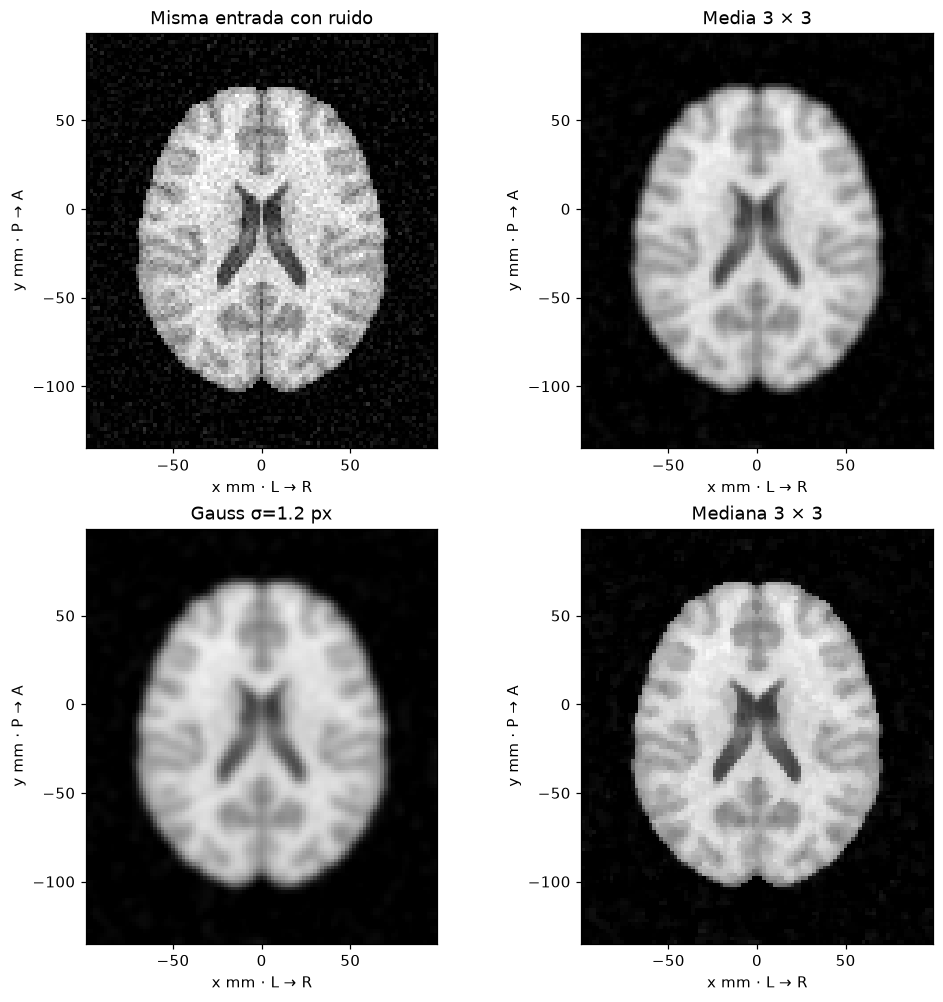

Sigma Gauss: 2.4 mm por eje del plano; ruido: mínimo -0.239, máximo 1.110


In [6]:
semilla = 2026
sigma_ruido = 0.06
sigma_pixeles = 1.2
rng = np.random.default_rng(semilla)
ruido = rng.normal(0, sigma_ruido, size=corte.shape).astype(np.float32)
ruidosa = corte + ruido
media = ndimage.uniform_filter(ruidosa, size=3, mode="reflect")
gauss = ndimage.gaussian_filter(ruidosa, sigma=sigma_pixeles, mode="reflect")
mediana = ndimage.median_filter(ruidosa, size=3, mode="reflect")
matrices = [ruidosa, media, gauss, mediana]
titulos = ["Misma entrada con ruido", "Media 3 × 3", f"Gauss σ={sigma_pixeles} px", "Mediana 3 × 3"]
fig, ax = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
for panel, matriz, titulo in zip(ax.ravel(), matrices, titulos):
    panel.imshow(matriz, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
    panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()
print(f"Sigma Gauss: {sigma_pixeles * pasos[0]:.1f} mm por eje del plano; ruido: mínimo {ruidosa.min():.3f}, máximo {ruidosa.max():.3f}")

### Prueba antes de consultar la solución

Cambia solo `sigma_pixeles` de 1.2 a 0.6 y después a 2.4. Predice qué detalles se conservarán o se suavizarán más. La semilla, el ruido y los otros filtros deben permanecer iguales.

**Pista:** en esta imagen cada píxel del plano mide 2 mm entre centros; sigma 1.2 px equivale a 2.4 mm por eje. Sigma no es el diámetro total del filtro ni una nueva resolución clínica.



<details>
<summary>Ver la solución explicada</summary>

Un sigma mayor mezcla información a distancias mayores: suele reducir fluctuaciones y borrar o ensanchar detalles. La imagen más lisa no es necesariamente la mejor para cualquier tarea. Los parámetros de media, Gauss y mediana no igualan exactamente su fuerza de suavizado: ilustramos comportamientos, sin declarar un ganador universal.

</details>

**Restaura `sigma_pixeles = 1.2` y ejecuta esta celda antes de la 7.** Si conservas otro sigma, los resultados de bordes cambiarán. El ruido original tiene extremos aproximados −0.239 y 1.110; la ventana de dibujo 0–1 solo satura su apariencia.

### Cada línea, para consultar después

1. Fija una realización reproducible del ruido para comparar operaciones con la misma entrada.
2. Controla la desviación del ruido en unidades relativas de intensidad.
3. Controla la anchura espacial del filtro gaussiano en muestras del corte.
4. Crea un generador independiente y reproducible.
5. Genera una variación de media cero por píxel; el ruido también alcanza el fondo.
6. Crea la imagen perturbada sin cambiar corte y sin recortar valores a cero y uno.
7. Promedia una vecindad 3×3 y refleja valores al tratar los límites de la imagen.
8. Suaviza la misma entrada con pesos gaussianos.
9. Elige la mediana de nueve vecinos en cada posición del corte 2D.
10. Reúne la entrada compartida y las tres salidas.
11. Declara qué operación y parámetro produjo cada panel.
12. Prepara cuatro paneles suficientemente grandes para mirar detalles.
13. Recorre la lista de paneles y sus matrices correspondientes.
14. Mantiene la ventana cero–uno común; no normaliza cada salida por separado.
15. Identifica la operación y la misma orientación física.
16. Presenta las cuatro imágenes para comparar ruido y detalles.
17. Convierte sigma a milímetros para esta rejilla y comprueba que la matriz ruidosa no fue recortada.

## Celda 7 · Sobel: medir cambios con una escala compartida

**50–55 minutos · Demostración comparativa.** Requiere la celda 6. Sobel calcula respuestas de cambio horizontal y vertical; combinamos ambas mediante una magnitud. Una zona brillante pero uniforme puede tener poca respuesta. El ruido también genera cambios.

Comparamos la misma entrada antes y después de Gauss. Conservamos un máximo de color común y el mismo umbral absoluto. La barra muestra **respuesta Sobel**, no intensidad RM ni una derivada calibrada por milímetro.

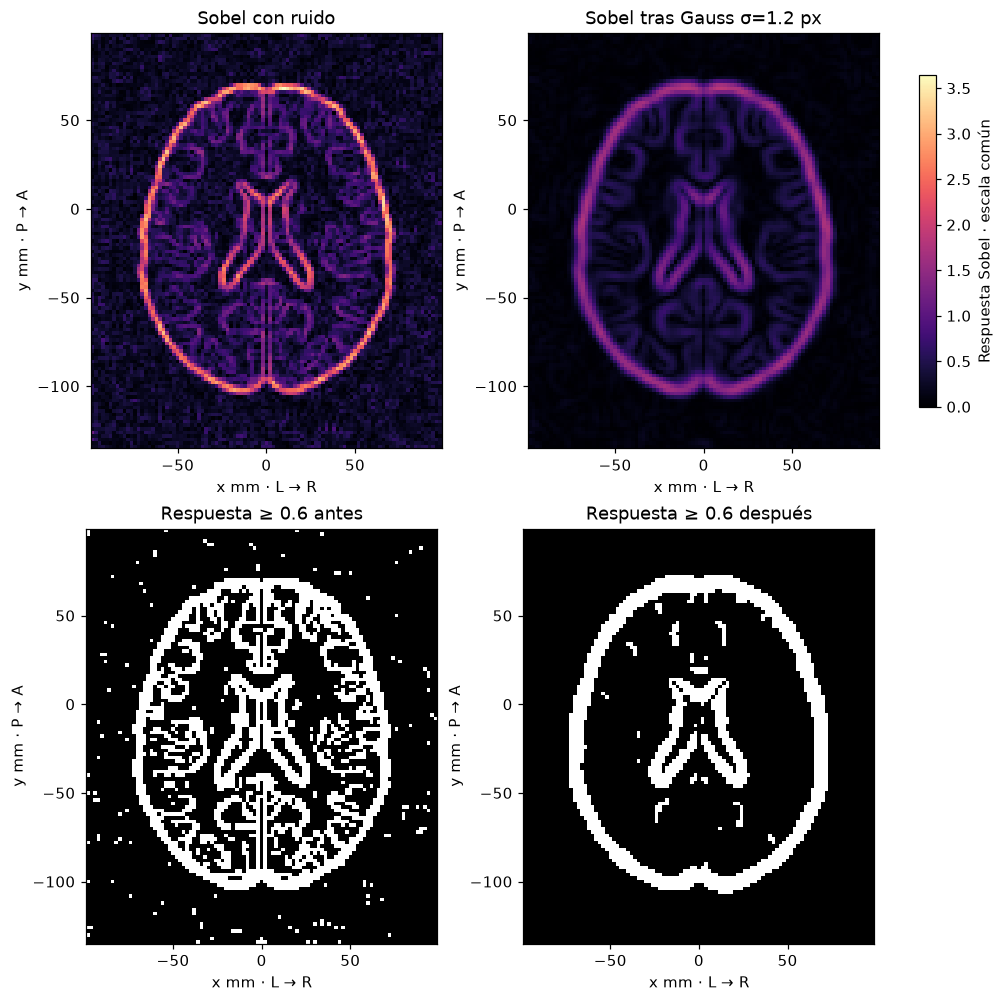

Umbral 0.6: seleccionados antes/después = 2471 / 1495


In [7]:
dx = ndimage.sobel(ruidosa, axis=1, mode="reflect")
dy = ndimage.sobel(ruidosa, axis=0, mode="reflect")
gradiente = np.sqrt(dx**2 + dy**2)
dx_suave = ndimage.sobel(gauss, axis=1, mode="reflect")
dy_suave = ndimage.sobel(gauss, axis=0, mode="reflect")
gradiente_suave = np.sqrt(dx_suave**2 + dy_suave**2)
maximo_comun = max(float(gradiente.max()), float(gradiente_suave.max()), 1e-12)
umbral_borde = 0.6
mapas = [gradiente, gradiente_suave, gradiente >= umbral_borde, gradiente_suave >= umbral_borde]
titulos = ["Sobel con ruido", f"Sobel tras Gauss σ={sigma_pixeles} px", f"Respuesta ≥ {umbral_borde} antes", f"Respuesta ≥ {umbral_borde} después"]
fig, ax = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
for indice, panel in enumerate(ax.ravel()):
    panel.imshow(mapas[indice], cmap="magma" if indice < 2 else "gray", origin="lower", extent=extension, vmin=0, vmax=maximo_comun if indice < 2 else 1)
    panel.set(title=titulos[indice], xlabel="x mm · L → R", ylabel="y mm · P → A")
fig.colorbar(ax[0, 0].images[0], ax=ax[0, :], shrink=0.8, label="Respuesta Sobel · escala común")
plt.show()
print(f"Umbral {umbral_borde}: seleccionados antes/después = {(gradiente >= umbral_borde).sum()} / {(gradiente_suave >= umbral_borde).sum()}")

### Predice y comprueba

Si queda tiempo, cambia `umbral_borde` de 0.6 a 0.8 en ambos mapas. ¿Aumentará el número de posiciones seleccionadas?

**Pista:** el criterio se vuelve más exigente y sigue aplicándose a las mismas magnitudes.



<details>
<summary>Ver la solución explicada</summary>

La selección disminuye o conserva su tamaño. Con corte 46, ruido 0.06, semilla 2026 y Gauss 1.2, el umbral 0.6 selecciona **2 471 posiciones antes y 1 495 después**. Esa reducción no demuestra que los puntos eliminados fueran errores: el suavizado también puede borrar detalles reales. No normalizamos por separado los dos gradientes, porque eso haría que un mismo color o umbral representara respuestas originales distintas.

</details>

### Cada línea, para consultar después

1. Aproxima cambios al recorrer columnas, que aquí corresponden a x.
2. Aproxima cambios al recorrer filas, que aquí corresponden a y.
3. Combina las dos respuestas mediante su magnitud; elimina el signo de cada dirección.
4. Calcula el cambio horizontal después del Gauss de la celda 6.
5. Calcula el cambio vertical sobre esa misma imagen suavizada.
6. Obtiene la magnitud después del suavizado.
7. Fija una escala compartida y evita un extremo superior nulo en una entrada constante.
8. Elige un mismo valor de respuesta para las dos máscaras de borde.
9. Reúne las magnitudes y las selecciones binarias construidas con la misma regla.
10. Distingue magnitudes de selecciones y registra el sigma realmente usado.
11. Crea una fila de magnitudes y otra de máscaras.
12. Recorre los paneles con su posición para elegir el tipo de escala.
13. Usa la misma escala en ambas magnitudes y cero–uno en ambas máscaras.
14. Conserva títulos y coordenadas de la comparación.
15. Añade una barra que pertenece a las magnitudes de la primera fila.
16. Presenta los mapas sin ocultar diferencias mediante normalizaciones independientes.
17. Cuenta posiciones que superan la regla; no las interpreta como aciertos o diagnósticos.

## Celda 8 · Explicar el recorrido y sus límites

**55–60 minutos · Evaluación de salida.** Requiere `plt` de la celda 1; interpreta el recorrido después de las celdas 2–7. Ejecuta el mapa y responde las tres preguntas que aparecen debajo antes de leer sus soluciones.

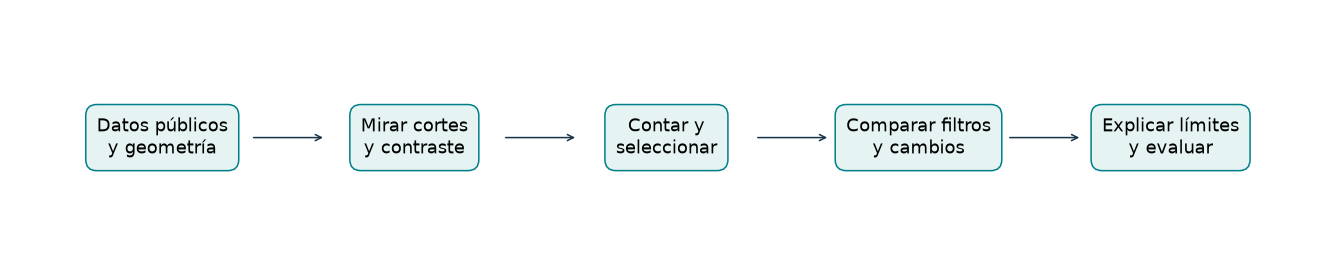

In [8]:
etapas = ["Datos públicos\ny geometría", "Mirar cortes\ny contraste", "Contar y\nseleccionar", "Comparar filtros\ny cambios", "Explicar límites\ny evaluar"]
fig, ax = plt.subplots(figsize=(12, 2.4), layout="constrained")
ax.set(xlim=(-0.6, 4.6), ylim=(-0.6, 0.6))
ax.axis("off")
for indice, texto in enumerate(etapas):
    ax.text(indice, 0, texto, ha="center", va="center", fontsize=12, bbox={"boxstyle": "round,pad=0.6", "facecolor": "#e5f3f3", "edgecolor": "#007f89"})
    if indice < len(etapas)-1:
        ax.annotate("", xy=(indice+0.65, 0), xytext=(indice+0.35, 0), arrowprops={"arrowstyle": "->", "color": "#18354a"})
plt.show()

### Tres preguntas, primero sin soluciones

1. Al cambiar `vmin` y `vmax`, una región se ve más blanca. ¿Demuestra que sus valores aumentaron?
2. Una máscara selecciona intensidades altas. ¿Demuestra que ha localizado enfermedad?
3. Si una persona aporta 100 cortes, ¿podemos repartir unos en entrenamiento y otros en prueba para evaluar generalización a personas nuevas?



<details>
<summary>Ver la solución explicada</summary>

1. **No.** Cambió la traducción visual. Hay que comparar matrices para demostrar un cambio de valores.
2. **No.** Solo muestra posiciones que cumplen una regla. El significado clínico requiere definición, referencia y validación.
3. **No es una separación apropiada para esa pregunta.** Las imágenes de la misma persona deben mantenerse juntas. Separar por paciente evita que características de una persona aparezcan en entrenamiento y prueba; además se necesitan etiquetas fiables y un diseño de evaluación adecuado.

Una plantilla promedio no proporciona casos independientes para estimar sensibilidad o especificidad. Este taller enseña operaciones previas y lectura crítica; no presenta un clasificador ni una validación diagnóstica.

</details>

### Cada línea, para consultar después

1. Resume las preguntas que respondió el taller; no representa un modelo entrenado.
2. Reserva una franja horizontal para el mapa de la sesión.
3. Define coordenadas artificiales para distribuir las cinco etapas.
4. Oculta ejes que no representan medidas médicas.
5. Recorre los cinco pasos en el orden de trabajo.
6. Dibuja cada etapa como una tarjeta legible.
7. Añade flecha solo cuando existe una etapa siguiente.
8. Conecta las etapas sin atribuir causalidad clínica al dibujo.
9. Presenta la secuencia completa.

## Si algo no sale como esperabas

- **`NameError`:** vuelve a ejecutar desde la celda 1 en orden. Una variable se crea al ejecutar, no al leer.
- **Resultados distintos del texto:** revisa `k=46`, `percentil=90`, `nivel=0.7`, `semilla=2026`, `sigma_ruido=0.06`, `sigma_pixeles=1.2` y `umbral_borde=0.6`. Ejecuta otra vez las celdas dependientes.
- **Celda aún trabajando:** espera a que termine; la primera puede estar preparando bibliotecas. Las imágenes guardadas permiten seguir la explicación mientras tanto.
- **Sin conexión:** el notebook local necesita las bibliotecas ya preparadas y `datos/mni152_2mm.nii.gz` junto al proyecto. La carga alternativa en una sesión nueva de Colab puede requerir instalación.

## Antes de usar imágenes propias

Aquí no se solicitan archivos clínicos. Para usar datos de pacientes, confirma autorización y desidentifica copias en un entorno permitido **antes de subirlas** a Colab, GitHub o una herramienta de IA. DICOM puede contener identificadores en metadatos, campos privados, referencias y texto escrito en los píxeles; NIfTI y sus acompañantes pueden conservar información identificable y rasgos faciales. Cambiar el nombre o borrar un campo no completa el proceso. Si conservas una clave reversible, se trata de seudonimización. El apéndice del manual explica qué revisar; no se ofrece un script que prometa anonimización completa.

## Fuentes, procedencia y continuación

La entrada es la **plantilla T1 MNI152 distribuida por Nilearn**, en una rejilla de 2 mm. La edición validada usa Nilearn 0.12.1. La documentación de esa función describe una ICBM152 2009a asimétrica, mientras el nombre del archivo interno de esa versión incluye `sym_09a`: conservamos la discrepancia sin inferir una variante por el nombre. Datos, referencia y licencia íntegra están en [FUENTES_Y_LICENCIAS.txt](https://github.com/FisikMedik/taller-imagenes-medicas-python/blob/main/FUENTES_Y_LICENCIAS.txt). Este cuaderno no cambia esas condiciones.

- [Programa oficial](https://machine-learning-honduras.org/programa/) y [datos públicos de la agenda](https://machine-learning-honduras.org/assets/json/program-events.json).
- [Carga de MNI152, Nilearn 0.12.1](https://nilearn.github.io/0.12.1/modules/generated/nilearn.datasets.load_mni152_template.html) y [fuente McGill](https://www.bic.mni.mcgill.ca/ServicesAtlases/ICBM152NLin2009).
- [Geometría NiBabel](https://nipy.org/nibabel/coordinate_systems.html), [histogramas Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) y [curvas de nivel](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.contour.html).
- [Gauss](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.gaussian_filter.html), [media](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.uniform_filter.html), [mediana](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.median_filter.html) y [Sobel](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.sobel.html), documentación SciPy.
- [Perfiles DICOM de confidencialidad](https://dicom.nema.org/medical/dicom/current/output/chtml/part15/chapter_E.html) y [separación de datos agrupados](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data).

Continúa con el [cuaderno completo de 24 lecciones](https://github.com/FisikMedik/taller-imagenes-medicas-python/blob/main/Taller_imagenes_medicas.ipynb) y el [manual ilustrado](https://github.com/FisikMedik/taller-imagenes-medicas-python/blob/main/Guia_visual_imagenes_medicas.pdf). El material completo añade matrices pequeñas, cálculos a mano y ruido de impulsos. Son ampliaciones posteriores, no tareas obligatorias dentro de esta hora.

**Preparado para la sesión de la escuela · revisión del 23 de noviembre de 2026.**